# 02. Modelling and evaluation

**Project:** pmt-Burundi, poverty classification with Proxy Means Testing (DSA 8401 capstone)

**Purpose:** compare three techniques for predicting `poor` from the 111 observable predictors, and evaluate them honestly.

**Input:** `data/processed/clean.csv`, produced by `src/preprocess.py` (restricted data, not included in the repository).

**Output:** the chosen technique and its settings, which feed `src/train.py`. This notebook does not write any household data.

## What to expect

1. **Load and split**: train and test sets, with each cluster kept on one side.
2. **Baseline**: the score of a trivial guess.
3. **Three techniques**: logistic regression, random forest and XGBoost.
4. **Evaluation**: who is missed and who is wrongly included.
5. **Choice and interpretation**: which technique, and which predictors matter most.
6. **Fairness check**: errors by residence and by sex of the head.

## Step 1. Load and split
Loads the clean table and splits it into a training set and a test set, keeping each cluster on one side so that the test score is honest.

In [1]:
# Step 1, Part 1: Load the clean table and split it into train and test, keeping each cluster on one side

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Settings in one place, so the split can be reproduced exactly.
DATA_PATH = "../data/processed/clean.csv"
SEED = 42
TEST_SHARE = 0.20

# Load the table produced by src/preprocess.py.
data = pd.read_csv(DATA_PATH)
print("Table:", data.shape)

# Separate the three roles: predictors (X), the answer (y), and the cluster number (groups, used only for the split).
predictors = [c for c in data.columns if c not in ("hh1", "poor")]
X, y, groups = data[predictors], data["poor"], data["hh1"]
print("Predictors:", len(predictors), "| poor share:", round(y.mean() * 100, 1), "%")

# Split by cluster: every household of a cluster lands on the same side, so neighbours cannot inflate the test score.
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=TEST_SHARE, random_state=SEED).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

# Checks: sizes, clusters per side, no cluster on both sides, similar class balance.
print("\nTrain:", len(X_train), "households,", groups.iloc[train_idx].nunique(), "clusters | poor:", round(y_train.mean() * 100, 1), "%")
print("Test: ", len(X_test), "households,", groups.iloc[test_idx].nunique(), "clusters | poor:", round(y_test.mean() * 100, 1), "%")
print("Clusters on both sides:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Table: (7407, 113)
Predictors: 111 | poor share: 43.9 %

Train: 5932 households, 521 clusters | poor: 43.6 %
Test:  1475 households, 131 clusters | poor: 45.2 %
Clusters on both sides: 0


## Step 2. Baseline
Scores two trivial guesses on the test set. A model is only useful if it clearly beats them.

In [2]:
# Step 2, Part 1: Baselines, the scores any model must beat

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Helper: the four scores used throughout the notebook, with poor (1) as the group we want to find.
def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "recall (poor found)": recall_score(y_true, y_pred),
            "precision (flagged who are poor)": precision_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred)}

# Baseline 1: call every household "not poor" (the majority class).
base_all_not_poor = np.zeros(len(y_test), dtype=int)

# Baseline 2: one simple rule, "rural means poor" (hh6 = 1 is Rural in the codebook).
base_rural_rule = (X_test["hh6"] == 1).astype(int).to_numpy()

# Both baselines on the test set. Nothing is trained here, so the test set is not used up.
baselines = pd.DataFrame({"everyone not poor": scores(y_test, base_all_not_poor),
                          "rural = poor": scores(y_test, base_rural_rule)}).round(3)
display(baselines)

,everyone not poor,rural = poor
accuracy,0.548,0.537
recall (poor found),0.000,0.980
precision (flagged who are poor),0.000,0.494
f1,0.000,0.657


## Step 3. Three techniques
Compares logistic regression, random forest and XGBoost with 5-fold cross-validation on the training set, grouped by cluster. The test set stays untouched until Step 4.

In [3]:
# Step 3, Part 1: Column types, a shared evaluation helper, and the first technique (logistic regression)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Column types come from the data dictionary saved by notebook 01 (Step 9, Part 2).
dictionary = pd.read_csv("../docs/data_dictionary.csv", encoding="utf-8-sig").set_index("code")
cat_cols = [c for c in predictors if dictionary.loc[c, "type"] == "category"]
num_cols = [c for c in predictors if c not in cat_cols]
print(len(cat_cols), "category columns |", len(num_cols), "numeric columns")

# One helper for all three techniques: 5-fold cross-validation on the training set, folds grouped by cluster.
cv = GroupKFold(n_splits=5)
metrics = ["accuracy", "recall", "precision", "f1"]
cv_results = {}

def evaluate(name, model):
    out = cross_validate(model, X_train, y_train, groups=groups_train, cv=cv, scoring=metrics)
    cv_results[name] = {m: out[f"test_{m}"].mean() for m in metrics}
    cv_results[name]["f1 spread"] = out["test_f1"].std()
    return pd.DataFrame(cv_results).T.round(3)

# Logistic regression needs numbers on a common scale: categories become 0/1 columns (an empty cell is its own level),
# numeric columns are filled with the median (plus a flag showing it was empty) and standardised.
prep = ColumnTransformer([
    ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value=-1)),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), num_cols)])
logreg = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

# Cross-validate the first technique.
evaluate("logistic regression", logreg)

51 category columns | 60 numeric columns


,accuracy,recall,precision,f1,f1 spread
logistic regression,0.701,0.617,0.67,0.642,0.022


In [4]:
# Step 3, Part 2: Same table, same data: the rural rule, logistic regression, random forest and XGBoost

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# Add ROC AUC to the scores and start the table again, so every row is measured the same way.
metrics = ["accuracy", "recall", "precision", "f1", "roc_auc"]
cv_results = {}

# Baseline on the training set (no model is trained for a rule): "rural means poor".
rural_train = (X_train["hh6"] == 1).astype(int)
cv_results["rule: rural = poor"] = {"accuracy": accuracy_score(y_train, rural_train), "recall": recall_score(y_train, rural_train),
                                    "precision": precision_score(y_train, rural_train), "f1": f1_score(y_train, rural_train),
                                    "roc_auc": roc_auc_score(y_train, rural_train), "f1 spread": np.nan}

# Technique 1 again, now with ROC AUC.
evaluate("logistic regression", logreg)

# Technique 2: random forest, many decision trees voting. Empty cells get the code -1 (trees can use it as a signal).
forest = Pipeline([("fill", SimpleImputer(strategy="constant", fill_value=-1)),
                   ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED))])
evaluate("random forest", forest)

# Technique 3: XGBoost, trees built one after another, each correcting the previous ones. It reads empty cells natively.
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    eval_metric="logloss", n_jobs=-1, random_state=SEED)
display(evaluate("xgboost", xgb))

,accuracy,recall,precision,f1,roc_auc,f1 spread
rule: rural = poor,0.493,0.959,0.461,0.622,0.546,NaN
logistic regression,0.701,0.617,0.670,0.642,0.756,0.022
random forest,0.709,0.587,0.697,0.637,0.769,0.019
xgboost,0.724,0.650,0.696,0.672,0.788,0.021


## Step 4. Evaluation
Checks the chosen technique (XGBoost) once on the untouched test set, and shows who is found, who is missed and who is wrongly flagged.

In [5]:
# Step 4, Part 1: The chosen technique (XGBoost) on the untouched test set

from sklearn.metrics import confusion_matrix

# Train XGBoost on the full training set, then predict the test households (poor if the predicted risk is 0.5 or more).
xgb.fit(X_train, y_train)
proba = xgb.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

# Test scores next to the two baselines of Step 2.
test_table = pd.DataFrame({"everyone not poor": scores(y_test, base_all_not_poor),
                           "rural = poor": scores(y_test, base_rural_rule),
                           "xgboost": scores(y_test, pred)})
test_table.loc["roc_auc"] = [0.5, roc_auc_score(y_test, base_rural_rule), roc_auc_score(y_test, proba)]
display(test_table.round(3))

# Who is found, missed and wrongly flagged (the 2 x 2 table, in counts of households).
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Truly poor: {tp + fn} | found: {tp} | missed: {fn}")
print(f"Truly not poor: {tn + fp} | correctly left out: {tn} | wrongly flagged as poor: {fp}")

,everyone not poor,rural = poor,xgboost
accuracy,0.548,0.537,0.734
recall (poor found),0.000,0.980,0.680
precision (flagged who are poor),0.000,0.494,0.717
f1,0.000,0.657,0.698
roc_auc,0.500,0.576,0.801


Truly poor: 666 | found: 453 | missed: 213
Truly not poor: 809 | correctly left out: 630 | wrongly flagged as poor: 179


## Step 5. Choice and interpretation
Shows which predictors XGBoost relies on most, one by one and by group.

In [6]:
# Step 5, Part 1: Which predictors does XGBoost rely on most?

# Importance of each predictor in the model trained in Step 4 (its share of the total), with English names.
imp = pd.Series(xgb.feature_importances_, index=predictors).sort_values(ascending=False)
top = pd.DataFrame({"name": [str(dictionary.loc[c, "english_name"])[:55] for c in imp.index[:15]],
                    "importance_%": (imp.iloc[:15] * 100).round(1)})
top["bar"] = ["#" * int(v / imp.iloc[0] * 25) for v in imp.iloc[:15]]
display(top)
print("Top 15 predictors:", round(imp.iloc[:15].sum() * 100, 1), "% of the total importance")

# The same importance, summed by group of variables.
def group(c):
    if c.startswith("hc9_"): return "durable assets"
    if c.startswith("hc"): return "dwelling and land"
    if c.startswith("ws"): return "water and sanitation"
    if c.startswith("tn"): return "mosquito nets"
    if c in ("hhage", "hhsex", "hhmstatus", "helevel"): return "head of household"
    return "size, location, activities"
display((imp.groupby(imp.index.map(group)).sum() * 100).round(1).sort_values(ascending=False).to_frame("importance_%"))

,name,importance_%,bar
hc17_1,What means of communication does the household...,7.3,#########################
hc9_9,Mobile phone,5.9,####################
hc9_14,Dining table,5.8,###################
hc17_3,What means of communication does the household...,3.2,##########
tn7_4,"In your opinion, what factors prevent people f...",2.1,######
hc9_24,Axe,2.0,######
hc16_1,What means of information does the household o...,1.9,######
hc13,"Does your household own livestock, a herd, or ...",1.9,######
hc6,What type of fuel does your household mainly u...,1.7,#####
helevel,Education level of head of household,1.7,#####


Top 15 predictors: 40.4 % of the total importance


,importance_%
dwelling and land,42.0
durable assets,21.9
mosquito nets,14.5
water and sanitation,10.4
"size, location, activities",7.7
head of household,3.6


In [7]:
# Step 5, Part 2: What exactly are the top predictors? Full question and meaning of the values

for c in ["hc17_1", "hc17_3", "hc16_1", "hc18_1", "tn7_4"]:
    print(f"{c}: {dictionary.loc[c, 'english_name']}")
    print("   ", dictionary.loc[c, "values"])

hc17_1: What means of communication does the household own: None
    nan
hc17_3: What means of communication does the household own: Mobile phone
    nan
hc16_1: What means of information does the household own: None
    nan
hc18_1: What means of transport does the household own: None
    nan
tn7_4: In your opinion, what factors prevent people from using mosquito nets? Have harmful effects
    nan


## Step 6: How many questions do we really need?

Roadmap: Part 1 load the same split, Part 2 rank the predictors, Part 3 score shorter lists with cross-validation, Part 4 chart, Part 5 choose the list, test it once and save it.

In [8]:
# Part 1: load the same households, in the same train/test split, as src/train.py.
import sys
from pathlib import Path

import pandas as pd

# Make the src folder importable, whether the notebook runs from notebooks/ or from the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))

# Reuse the function and settings from train.py, so the notebook cannot drift away from the script.
from train import load_and_split, DATA_FILE, CLUSTER_COLUMN, SEED, XGB_PARAMS

predictors, X_train, X_test, y_train, y_test = load_and_split()

# load_and_split does not return the cluster of each household, but GroupKFold in Part 3 needs it.
# X_train keeps the original row labels, so we fetch the clusters of the training rows by those labels.
groups_train = pd.read_csv(DATA_FILE).loc[X_train.index, CLUSTER_COLUMN]

print("Predictors:", len(predictors))
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Clusters in train:", groups_train.nunique())
print("Share poor in train:", round(y_train.mean(), 3), "| in test:", round(y_test.mean(), 3))

Predictors: 111
Train: (5932, 111) | Test: (1475, 111)
Clusters in train: 521
Share poor in train: 0.436 | in test: 0.452


Dictionary columns: ['code', 'english_name', 'type', 'values']
Using 'code' as the code and 'english_name' as the readable name

Top  3 predictors hold 19% of the total importance
Top  5 predictors hold 24% of the total importance
Top 10 predictors hold 33% of the total importance
Top 20 predictors hold 46% of the total importance


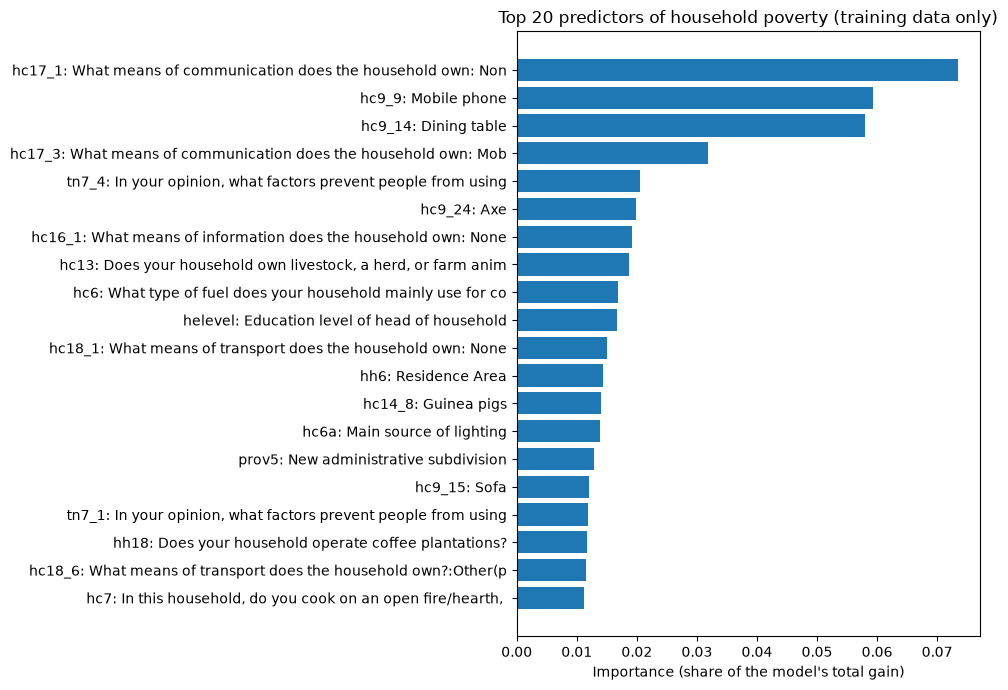

         importance                                           question
hc17_1        0.073  What means of communication does the household...
hc9_9         0.059                                       Mobile phone
hc9_14        0.058                                       Dining table
hc17_3        0.032  What means of communication does the household...
tn7_4         0.021  In your opinion, what factors prevent people f...
hc9_24        0.020                                                Axe
hc16_1        0.019  What means of information does the household o...
hc13          0.019  Does your household own livestock, a herd, or ...
hc6           0.017  What type of fuel does your household mainly u...
helevel       0.017               Education level of head of household
hc18_1        0.015  What means of transport does the household own...
hh6           0.014                                     Residence Area
hc14_8        0.014                                        Guinea pigs
hc6a  

In [9]:
# Part 2: rank the 111 predictors by importance, using the TRAINING data only.
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

# Same model settings as train.py. importance_type="gain" scores each predictor by how much it
# improves the model's predictions each time it is used (higher = the model leans on it more).
ranker = XGBClassifier(**XGB_PARAMS, importance_type="gain")
ranker.fit(X_train, y_train)

# One score per predictor, scaled so that all 111 scores add up to 1 (= 100%).
ranking = pd.Series(ranker.feature_importances_, index=predictors).sort_values(ascending=False)

# Readable names from the data dictionary. We print its columns first in case they are named differently.
dd = pd.read_csv(ROOT / "docs" / "data_dictionary.csv")
print("Dictionary columns:", dd.columns.tolist())
code_col = dd.columns[0]
label_col = next((c for c in dd.columns if "label" in c.lower() or "question" in c.lower()), dd.columns[1])
print(f"Using '{code_col}' as the code and '{label_col}' as the readable name\n")
names = dd.set_index(code_col)[label_col].to_dict()

# How much of the total importance sits in the first few questions?
for k in (3, 5, 10, 20):
    print(f"Top {k:>2} predictors hold {ranking.head(k).sum():.0%} of the total importance")

# Horizontal bar chart of the top 20, most important at the top.
top = ranking.head(20)
labels = [f"{c}: {str(names.get(c, ''))[:55]}" for c in top.index]
plt.figure(figsize=(10, 7))
plt.barh(labels[::-1], top.values[::-1])
plt.xlabel("Importance (share of the model's total gain)")
plt.title("Top 20 predictors of household poverty (training data only)")
plt.tight_layout()
plt.show()

# Table of the top 20 for reading the exact numbers.
print(top.round(3).to_frame("importance").assign(question=[str(names.get(c, ''))[:60] for c in top.index]))

In [10]:
# Part 3: group the 111 predictors by the question they come from, so we can decide the topics together.
import re

# A code like hc9_9 or hc6a belongs to question "hc9" or "hc6": the letters plus the first number.
# So all the items of one question (hc9_1, hc9_2, ...) fall into the same group.
def question_stem(code):
    m = re.match(r"[a-z]+\d*", code)
    return m.group(0) if m else code

stem = pd.Series({c: question_stem(c) for c in predictors})

# One row per question group: how many predictors it holds, how much importance together, and its strongest one.
groups = (pd.DataFrame({"stem": stem, "importance": ranking})
          .groupby("stem")
          .agg(items=("importance", "size"), total_importance=("importance", "sum"), best_item=("importance", "idxmax")))
groups["best_item_name"] = [str(names.get(c, ""))[:70] for c in groups["best_item"]]
groups = groups.sort_values("total_importance", ascending=False)
groups["total_importance"] = groups["total_importance"].round(3)

# Show every row (there are not many) so we can read the whole list.
pd.set_option("display.max_rows", None, "display.max_colwidth", 80, "display.width", 200)
print(len(groups), "question groups from", len(predictors), "predictors\n")
print(groups)

48 question groups from 111 predictors

           items  total_importance  best_item                                                          best_item_name
stem                                                                                                                 
hc9           24             0.219      hc9_9                                                            Mobile phone
hc17           5             0.123     hc17_1                What means of communication does the household own: None
hc14           8             0.060     hc14_8                                                             Guinea pigs
tn7            5             0.056      tn7_4  In your opinion, what factors prevent people from using mosquito nets?
hc16           5             0.047     hc16_1                  What means of information does the household own: None
tn3            7             0.044     tn3a_4              Where do you find them? Health Center, Vaccination Service
hc18           5

In [11]:
# Part 4: give every question a topic, remove the excluded ones, then build the candidate short lists.

# The 8 topics, written as question groups (the "stem" column of Part 3). Each group appears exactly once.
TOPICS = {
    "Household goods":                       ["hc9"],
    "Livestock, land and farm work":         ["hc11", "hc12", "hc13", "hc14", "hh17", "hh18", "hh20"],
    "Communication, information, transport": ["hc16", "hc17", "hc18"],
    "Dwelling and energy":                   ["hc1", "hc2", "hc3", "hc4", "hc5", "hc6", "hc7", "hc8", "hc15"],
    "Water and sanitation":                  ["ws1", "ws2", "ws3", "ws4", "ws5", "ws6", "ws7", "ws8", "ws9", "ws10", "ws11"],
    "Household head and size":               ["helevel", "hhage", "hhsex", "hhmstatus", "hh11", "hh12", "hh14"],
    "Location":                              ["hh6", "hh7", "prov5"],
    "Mosquito nets":                         ["tn1", "tn2", "tn4", "tn5", "tn6"],
}
EXCLUDED_STEMS = ["tn3", "tn7"]   # Decision A: opinion and service questions stay in the full model only
EXCLUDED_CODES = ["hc17_3"]       # Decision B: same fact as hc9_9 (mobile phone)

topic_of = {s: t for t, stems in TOPICS.items() for s in stems}

# Safety check: every question group must have a topic or be excluded on purpose.
unassigned = [s for s in groups.index if s not in topic_of and s not in EXCLUDED_STEMS]
print("Question groups without a topic:", unassigned)

# The pool of allowed predictors, strongest first (ranking is already sorted by importance).
pool = [c for c in ranking.index if stem[c] in topic_of and c not in EXCLUDED_CODES]
by_topic = {t: [c for c in pool if topic_of[stem[c]] == t] for t in TOPICS}
print("Predictors in the pool:", len(pool), "of", len(predictors), "\n")

def build_list(k):
    """Round 1 = best question of each topic, round 2 = second best of each topic, and so on; keep k."""
    picked, r = [], 0
    while len(picked) < k:
        this_round = [by_topic[t][r] for t in TOPICS if len(by_topic[t]) > r]
        if not this_round:
            break
        picked += sorted(this_round, key=lambda c: -ranking[c])   # strongest first inside the round
        r += 1
    return picked[:k]

# The strongest question of each topic = the 8-question list.
print("The 8 topic winners:\n")
for t in TOPICS:
    best = by_topic[t][0]
    print(f"{t:<40} {best:<8} {ranking[best]:.3f}  {str(names.get(best, ''))[:50]}")

Question groups without a topic: []
Predictors in the pool: 98 of 111 

The 8 topic winners:

Household goods                          hc9_9    0.059  Mobile phone
Livestock, land and farm work            hc13     0.019  Does your household own livestock, a herd, or farm
Communication, information, transport    hc17_1   0.073  What means of communication does the household own
Dwelling and energy                      hc6      0.017  What type of fuel does your household mainly use f
Water and sanitation                     ws7      0.011  What type of toilet facility do household members 
Household head and size                  helevel  0.017  Education level of head of household
Location                                 hh6      0.014  Residence Area
Mosquito nets                            tn6      0.010  Compared to your sleeping space, are the nets: lar


In [12]:
# Part 5: score each candidate list with 5-fold cross-validation INSIDE the training data (the test set is not touched).
import time
from sklearn.model_selection import GroupKFold, cross_validate

# The candidates: lists of different lengths built with the topic rule, plus two reference lists.
SIZES = [3, 5, 8, 10, 15, 20, 30]
candidates = {f"{k} questions": build_list(k) for k in SIZES}
candidates["Top 8 by rank only"] = list(ranking.index[:8])   # ignores topics, to see what the topic rule costs
candidates["All 111"] = list(predictors)                     # the full model, our reference

# GroupKFold keeps every cluster (hh1) on one side of each fold, like the real train/test split.
cv = GroupKFold(n_splits=5)
rows = []
for name, cols in candidates.items():
    start = time.time()
    res = cross_validate(XGBClassifier(**XGB_PARAMS), X_train[cols], y_train, groups=groups_train, cv=cv,
                         scoring=["roc_auc", "recall", "f1", "accuracy"])
    rows.append({"list": name, "questions": len(cols),
                 "auc": res["test_roc_auc"].mean(), "auc_sd": res["test_roc_auc"].std(),
                 "recall": res["test_recall"].mean(), "f1": res["test_f1"].mean(),
                 "accuracy": res["test_accuracy"].mean()})
    print(f"scored {name:<20} in {time.time() - start:.0f}s")

cv_results = pd.DataFrame(rows).sort_values(["questions", "list"]).reset_index(drop=True)

# How far is each list from the full model? (the selection rule we fixed BEFORE seeing the numbers)
full = cv_results[cv_results["list"] == "All 111"].iloc[0]
cv_results["auc_gap"] = full["auc"] - cv_results["auc"]
cv_results["recall_gap"] = full["recall"] - cv_results["recall"]
print()
print(cv_results.round(3).to_string(index=False))

# Suggested list: the smallest topic list within 0.01 AUC and 0.02 recall of the full model.
ok = cv_results[cv_results["list"].str.endswith("questions") & (cv_results["auc_gap"] <= 0.01) & (cv_results["recall_gap"] <= 0.02)]
print("\nSmallest list that passes the rule:", ok.iloc[0]["list"] if len(ok) else "none passes, we will discuss")

scored 3 questions          in 5s
scored 5 questions          in 5s
scored 8 questions          in 5s
scored 10 questions         in 5s
scored 15 questions         in 5s
scored 20 questions         in 5s
scored 30 questions         in 6s
scored Top 8 by rank only   in 5s
scored All 111              in 6s

              list  questions   auc  auc_sd  recall    f1  accuracy  auc_gap  recall_gap
       3 questions          3 0.677   0.010   0.554 0.552     0.624    0.112       0.096
       5 questions          5 0.697   0.016   0.595 0.596     0.648    0.091       0.055
       8 questions          8 0.709   0.018   0.548 0.583     0.659    0.080       0.102
Top 8 by rank only          8 0.713   0.011   0.606 0.610     0.664    0.076       0.044
      10 questions         10 0.724   0.015   0.582 0.606     0.671    0.064       0.068
      15 questions         15 0.751   0.013   0.608 0.631     0.690    0.038       0.042
      20 questions         20 0.767   0.014   0.622 0.649     0.707   

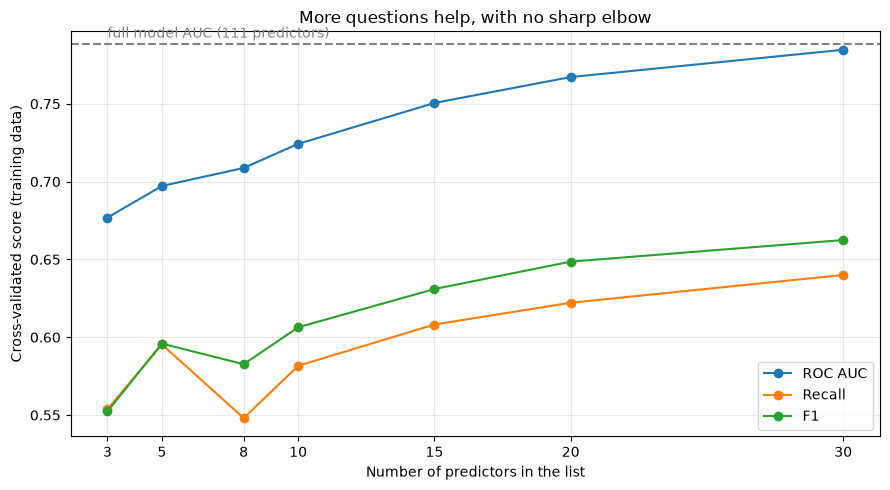


Predictors vs question groups the form would really need:
 8 predictors -> 8 question groups
10 predictors -> 9 question groups
15 predictors -> 13 question groups
20 predictors -> 17 question groups
30 predictors -> 24 question groups


In [13]:
# Part 6: chart of score against number of questions, plus how many QUESTION GROUPS each list really needs.
topic_lists = cv_results[cv_results["list"].str.endswith("questions")]

fig, ax = plt.subplots(figsize=(9, 5))
for col, label in [("auc", "ROC AUC"), ("recall", "Recall"), ("f1", "F1")]:
    ax.plot(topic_lists["questions"], topic_lists[col], marker="o", label=label)

# Dashed line = the full 111-predictor model, our reference for AUC.
ax.axhline(full["auc"], linestyle="--", color="grey")
ax.text(3, full["auc"] + 0.004, "full model AUC (111 predictors)", color="grey")

ax.set_xticks(topic_lists["questions"])
ax.set_xlabel("Number of predictors in the list")
ax.set_ylabel("Cross-validated score (training data)")
ax.set_title("More questions help, with no sharp elbow")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# A form asks QUESTIONS, and one question can hold many predictors (hc9_1, hc9_2, ... = one goods checklist).
print("\nPredictors vs question groups the form would really need:")
for k in (8, 10, 15, 20, 30):
    chosen = build_list(k)
    print(f"{k:>2} predictors -> {len({stem[c] for c in chosen})} question groups")

In [14]:
# Part 7: test it ONCE on the test households, and save the list.
import json
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

CHOSEN_K = 30                      # decided from the cross-validation table, BEFORE looking at the test set
chosen = build_list(CHOSEN_K)

# Train on all training households with the chosen questions only, then predict the test households.
final = XGBClassifier(**XGB_PARAMS).fit(X_train[chosen], y_train)
proba = final.predict_proba(X_test[chosen])[:, 1]
pred = (proba >= 0.5).astype(int)
short_scores = {"accuracy": accuracy_score(y_test, pred), "recall": recall_score(y_test, pred),
                "precision": precision_score(y_test, pred), "f1": f1_score(y_test, pred),
                "roc_auc": roc_auc_score(y_test, proba)}

# The full 111-predictor model's test scores were saved by train.py.
full_scores = json.loads((ROOT / "models" / "model_info.json").read_text())["test_metrics"]
print(f"TEST scores, {CHOSEN_K} predictors ({len({stem[c] for c in chosen})} questions) vs all 111:\n")
for m in short_scores:
    print(f"{m:<10} short {short_scores[m]:.3f}   full {full_scores[m]:.3f}")

# Save the list: one code per line for train.py, and a readable table for the README and the form.
(ROOT / "docs" / "short_predictors.txt").write_text("\n".join(chosen) + "\n")
table = pd.DataFrame({"code": chosen, "topic": [topic_of[stem[c]] for c in chosen],
                      "question_group": [stem[c] for c in chosen],
                      "question": [str(names.get(c, "")) for c in chosen],
                      "importance": [round(float(ranking[c]), 4) for c in chosen]})
table.to_csv(ROOT / "docs" / "short_predictors.csv", index=False)
print("\nSaved docs/short_predictors.txt and docs/short_predictors.csv with", len(chosen), "predictors")

TEST scores, 30 predictors (24 questions) vs all 111:

accuracy   short 0.719   full 0.734
recall     short 0.650   full 0.680
precision  short 0.704   full 0.717
f1         short 0.676   full 0.698
roc_auc    short 0.791   full 0.801

Saved docs/short_predictors.txt and docs/short_predictors.csv with 30 predictors


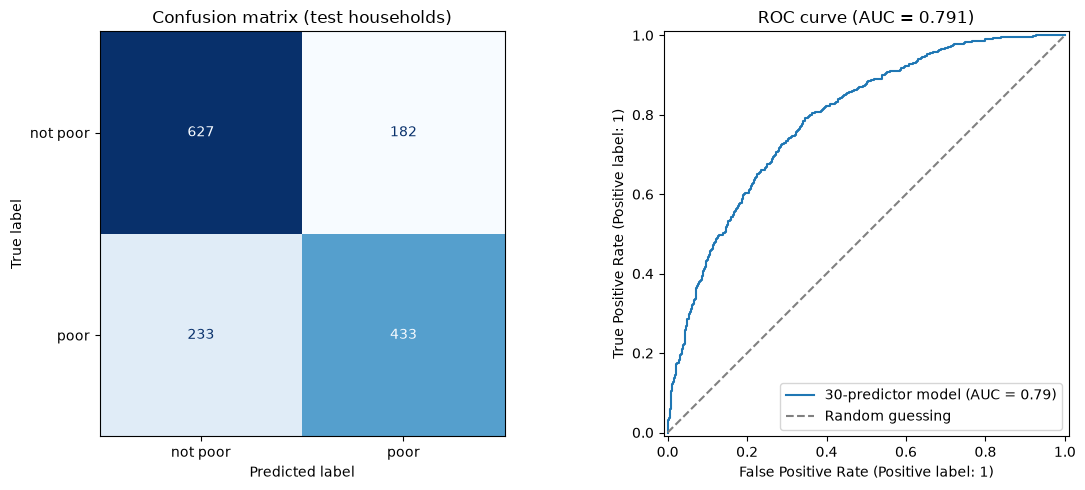

Poor households in the test data: 666
  found by the model (poor, said poor):    433
  missed by the model (poor, said not):    233
Not poor households: 809
  correctly left out (not poor, said not): 627
  wrongly flagged (not poor, said poor):   182


In [15]:
# Step 7, Part 1: confusion matrix and ROC curve of the 30-predictor model on the TEST households.
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: the four boxes (rows = the truth, columns = what the model said).
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not poor", "poor"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (test households)")

# Right: the ROC curve. The dashed diagonal is a coin flip; the more the curve bows to the top left, the better.
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name=f"{CHOSEN_K}-predictor model")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guessing")
axes[1].set_title(f"ROC curve (AUC = {short_scores['roc_auc']:.3f})")
axes[1].legend(loc="lower right")
plt.tight_layout()

# Save the picture so it can go straight into the slides.
(ROOT / "docs" / "figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "docs" / "figures" / "evaluation.png", dpi=200)
plt.show()

# The same four boxes in plain words.
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Poor households in the test data: {tp + fn}")
print(f"  found by the model (poor, said poor):    {tp}")
print(f"  missed by the model (poor, said not):    {fn}")
print(f"Not poor households: {tn + fp}")
print(f"  correctly left out (not poor, said not): {tn}")
print(f"  wrongly flagged (not poor, said poor):   {fp}")

In [16]:
# Print what the form needs: the 30 predictors with topic, question text, type and answer options.
info = (table[["code", "topic", "question"]]
        .assign(question=lambda d: d["question"].str[:60])
        .merge(dd[["code", "type", "values"]], on="code", how="left"))
pd.set_option("display.max_colwidth", 160, "display.width", 250)
print(info.to_string(index=False))

     code                                 topic                                                     question     type                                                                                                                                                                                                                                            values
   hc17_1 Communication, information, transport     What means of communication does the household own: None  numeric                                                                                                                                                                                                                                               NaN
    hc9_9                       Household goods                                                 Mobile phone    mixed                                                                                                                                                                   

In [17]:
# Data-driven demo households: the typical answers of the test households the model is most sure about.
import json

fields = {f["code"]: f["kind"] for f in json.loads((ROOT / "api" / "form_fields.json").read_text(encoding="utf-8"))}

test = X_test[chosen].copy()
test["risk"] = proba        # model risk of each test household (Step 6, Part 7)

# How common is poverty in each area? This is why "few assets" is not automatically "poor" in rural areas.
print("Share poor in the training data:", y_train.groupby(X_train["hh6"]).mean().round(3).to_dict(), "(1 = rural, 2 = urban)\n")

def typical(subset):
    """The usual answer of these households: the median for numbers, the most common answer for choices.
    A question that most of them left empty stays empty."""
    row = {}
    for c in chosen:
        col = subset[c].dropna()
        if len(col) < 0.5 * len(subset):
            continue
        row[c] = int(round(col.median())) if fields[c] == "number" else int(col.mode().iloc[0])
    return row

# Four profiles: truly poor (model most sure) and truly not poor (model most sure), in each area.
PROFILES = [("rural_poor", "Rural household, poor profile", 1, 1), ("urban_poor", "Urban household, poor profile", 2, 1),
            ("rural_better_off", "Rural household, better-off profile", 1, 0), ("urban_better_off", "Urban household, better-off profile", 2, 0)]

print("# ---- paste this over the whole EXAMPLES block in api/main.py ----")
print("EXAMPLES = {")
for key, summary, area, is_poor in PROFILES:
    rows = test[(test["hh6"] == area) & (y_test.loc[test.index] == is_poor)]
    subset = rows.nlargest(50, "risk") if is_poor else rows.nsmallest(50, "risk")
    row = typical(subset)
    risk = float(final.predict_proba(pd.DataFrame([row], columns=chosen).astype(float))[0, 1])
    print(f'    "{key}": {{"summary": "{summary}", "value": {{"answers": {row}}}}},   # model risk {risk:.0%}')
print("}")

Share poor in the training data: {1.0: 0.461, 2.0: 0.194} (1 = rural, 2 = urban)

# ---- paste this over the whole EXAMPLES block in api/main.py ----
EXAMPLES = {
    "rural_poor": {"summary": "Rural household, poor profile", "value": {"answers": {'hc17_1': 1, 'hc9_9': 0, 'hc13': 2, 'hc6': 5, 'helevel': 1, 'hh6': 1, 'ws7': 23, 'tn6': 2, 'hc9_14': 0, 'hc16_1': 1, 'hc14_8': 0, 'hc6a': 5, 'prov5': 3, 'ws5': 2, 'tn4': 1, 'hhage': 52, 'hc9_24': 0, 'hc18_1': 1, 'hh18': 3, 'hc7': 1, 'hh7': 2, 'ws9': 0, 'tn5': 8, 'hh12': 1, 'hc9_15': 0, 'hc18_6': 0, 'hc1c': 2, 'ws7a': 2, 'hc12': 2, 'hhmstatus': 1}}},   # model risk 83%
    "urban_poor": {"summary": "Urban household, poor profile", "value": {"answers": {'hc17_1': 0, 'hc9_9': 0, 'hc13': 2, 'hc6': 4, 'helevel': 2, 'hh6': 2, 'ws7': 22, 'tn6': 2, 'hc9_14': 0, 'hc16_1': 1, 'hc14_8': 0, 'hc6a': 1, 'prov5': 2, 'ws5': 2, 'tn4': 1, 'hhage': 43, 'hc9_24': 0, 'hc18_1': 1, 'hh18': 3, 'hc7': 1, 'hh7': 5, 'ws9': 1, 'tn5': 5, 'hh12': 1, 'hc9_15': 0, 'hc18_6':

In [18]:
# How many households carry a special code (97 or 98) in the count questions?
clean = pd.read_csv(DATA_FILE)
cols = ["hc9_9", "hc9_14", "hc9_24", "hc9_15", "hc14_8"]
print(clean[cols].isin([97, 98]).sum())
print("households in the clean table:", len(clean))

hc9_9     232
hc9_14    244
hc9_24    208
hc9_15     46
hc14_8     44
dtype: int64
households in the clean table: 7407


In [19]:
# Personal-data scan of the files we are about to commit.
# (Save the notebook first with Ctrl + S: the scan reads the saved file, outputs included.)
from ingest import load_data

raw = load_data()
text_cols = raw.select_dtypes(include="object").columns
raw_values = {str(v).strip() for c in text_cols for v in raw[c].dropna().unique() if len(str(v).strip()) >= 4}
print(f"Raw text values to look for: {len(raw_values)} (from {len(text_cols)} text columns)\n")

KEYWORDS = ["latitude", "longitude", "gps", "interview__key", "interview__id", "interview_key", "interview_id"]
FILES = ["notebooks/02_modelling.ipynb", "docs/short_predictors.csv", "docs/data_dictionary.csv",
         "docs/decision_log.md", "api/form_fields.json", "models/model_info.json", "src/train.py", "api/main.py"]

for name in FILES:
    path = ROOT / name
    if not path.exists():
        print(f"{name:<32} (not found)")
        continue
    text = path.read_text(encoding="utf-8", errors="ignore")
    keyword_hits = [k for k in KEYWORDS if k in text.lower()]
    value_hits = sorted(v for v in raw_values if v in text)
    print(f"{name:<32} keywords: {keyword_hits or 'none'} | raw values found: {len(value_hits)} {value_hits[:5]}")

C:\Users\dsimiyu\AppData\Local\Temp\ipykernel_35300\567244548.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = raw.select_dtypes(include="object").columns


Raw text values to look for: 39959 (from 10 text columns)

notebooks/02_modelling.ipynb     keywords: ['gps'] | raw values found: 0 []
docs/short_predictors.csv        keywords: none | raw values found: 0 []
docs/data_dictionary.csv         keywords: none | raw values found: 0 []
docs/decision_log.md             keywords: none | raw values found: 0 []
api/form_fields.json             keywords: none | raw values found: 0 []
models/model_info.json           keywords: none | raw values found: 0 []
src/train.py                     keywords: none | raw values found: 0 []
api/main.py                      keywords: none | raw values found: 0 []
